# W09B A · 잔차·영향력

2026-10-28 · **R 커널** · A/B는 각각 새 런타임에서 독립 실행됩니다. 로딩 후 준비 셀부터 실행하고 오류를 숨기지 않습니다.

먼저 예상→손계산→실행→설명을 적습니다. 필수 L01–L06과 확장 L07–L12의 질문은 계산 기록지와 같습니다. TODO는 주석이어서 미완성 상태여도 기본 예제가 끝까지 실행됩니다. 문제용 변수와 실행 예제 변수를 구별하세요. 온라인 R·R/QMD·R Colab은 한 경로를 선택합니다. 준비 파일을 자동으로 내려받고 캐시의 MD5 동일성을 확인합니다. 공개 릴리스의 SHA-256 검증과는 구별합니다. 재시작 후 준비 셀부터 다시 실행하세요.

공통 함수 고정 버전은 **2026-fall-w09b**입니다. [입력·출력·실제 정의 바로가기](https://github.com/lunalab-ai/regre/blob/2026-fall-w09b/src/diagnostics-influence-api.md). `source()`는 함수를 읽고 `lm()`은 모형을 적합하며 진단 함수는 그 적합을 읽습니다. 공식 경주 자료는 초/마일/피트를 사용합니다. NY 단순모형과 네 변수 모형을 구분합니다.

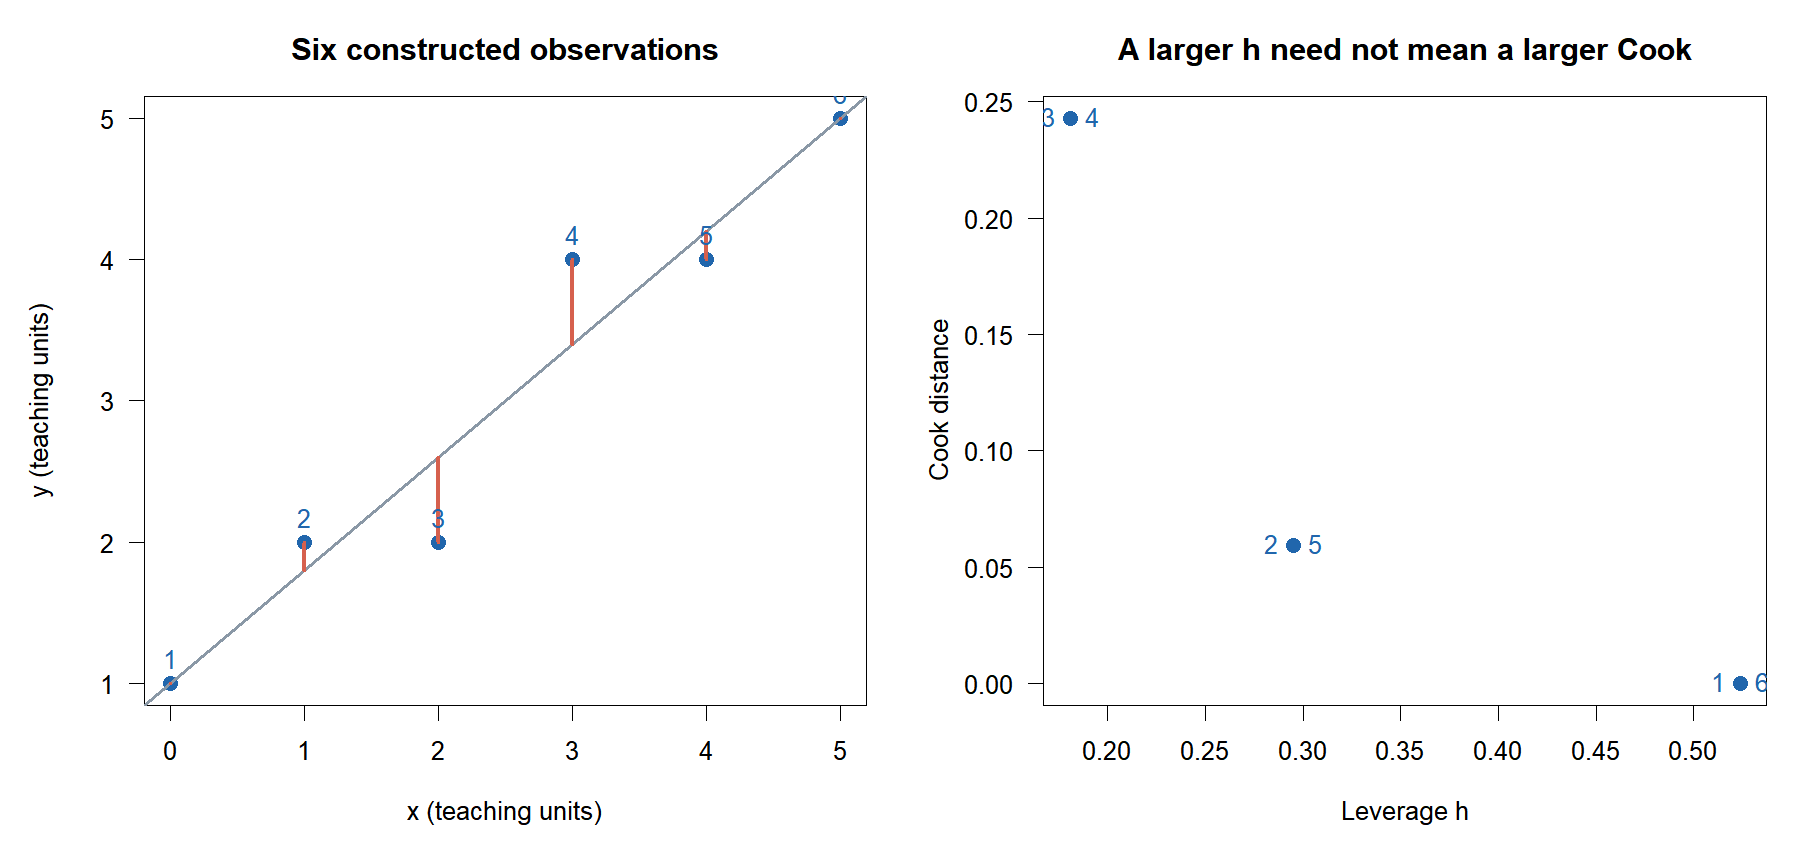

교재 5장의 개념을 표시된 교육용/공식 자료로 직접 재계산해 그린 그림입니다. [고정 버전 원본](https://github.com/lunalab-ai/regre/blob/2026-fall-w09b/course/notion/w09b/images/w09b-six.png).

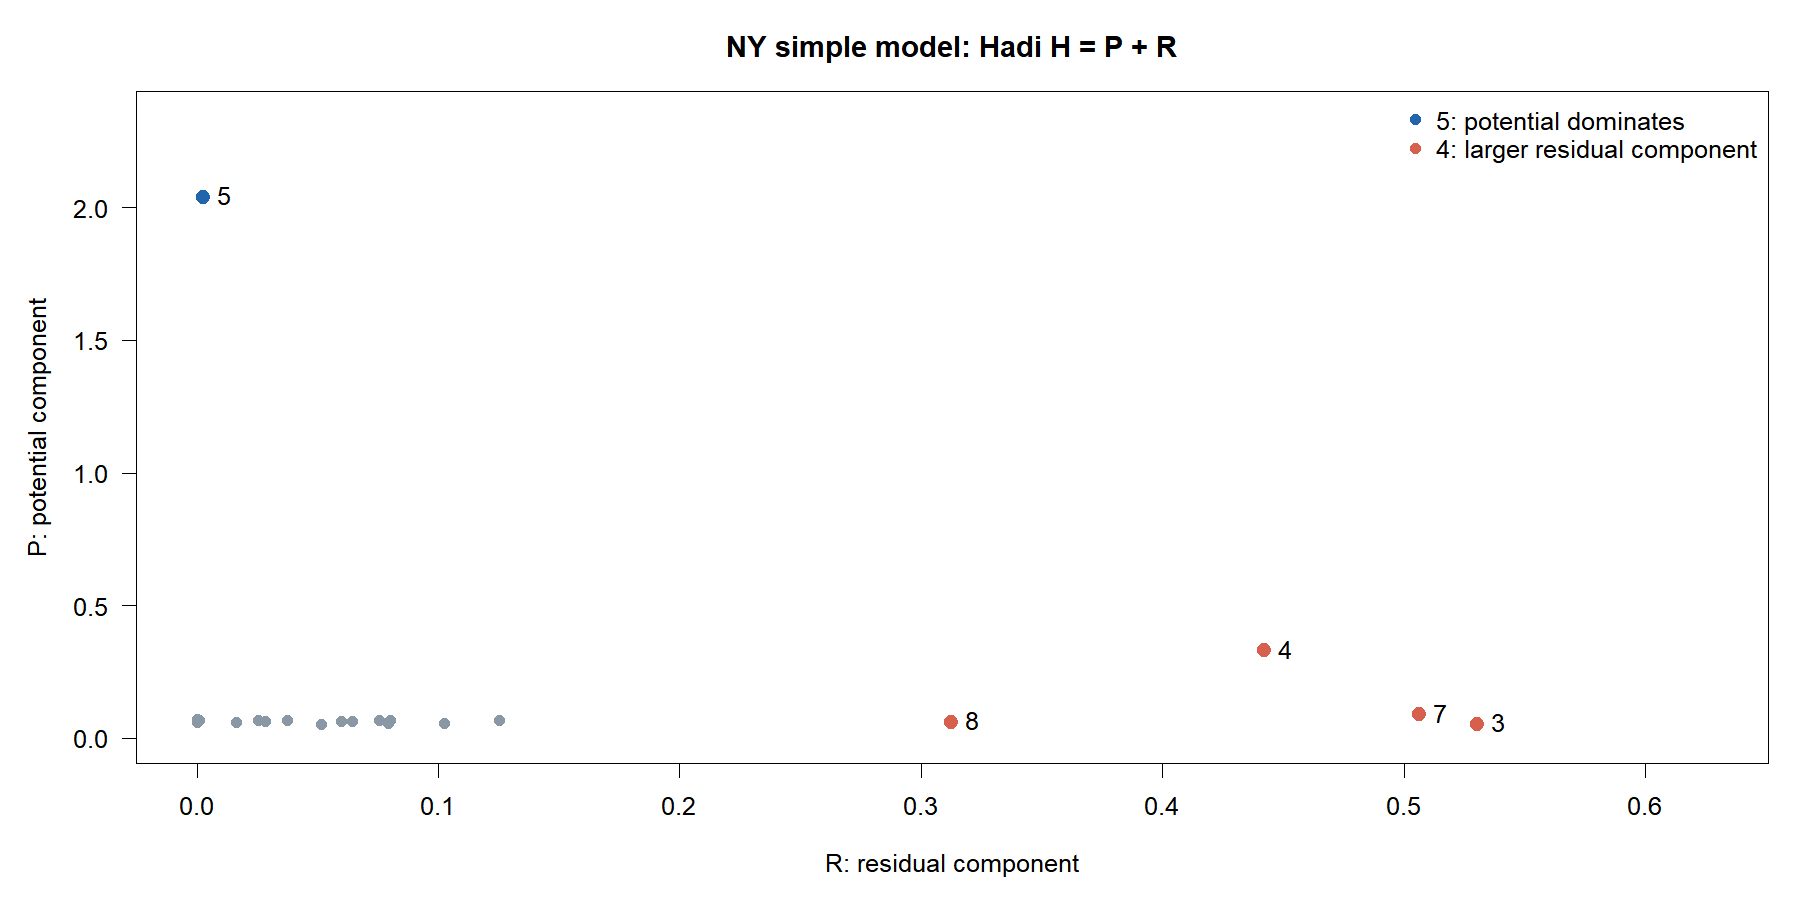

교재 5장의 개념을 표시된 교육용/공식 자료로 직접 재계산해 그린 그림입니다. [고정 버전 원본](https://github.com/lunalab-ai/regre/blob/2026-fall-w09b/course/notion/w09b/images/w09b-ny-pr.png).

## 0. 독립 실행 준비

데이터 업로드·API 키가 필요 없습니다. 로컬 R/QMD는 data 폴더를 함께 두고, R Colab은 고정 버전의 필요한 파일만 자동 준비합니다.

In [ ]:
tag <- "2026-fall-w09b"
local_dirs <- c("data","labs/student/w09b/data","../../labs/student/w09b/data","../../../labs/student/w09b/data")
found <- local_dirs[file.exists(file.path(local_dirs,"diagnostics-influence.R"))]
data_dir <- if(length(found)) found[1] else file.path(path.expand("~"),".cache","regre",tag)
dir.create(data_dir,recursive=TRUE,showWarnings=FALSE)
expected <- c("diagnostics-base-w09b.R"="1d6d198179eb52922e0b7da3a3836838","diagnostics-influence.R"="106f87499e0a0565f4c19d75b7e26c9a","diagnostics-effects.R"="df333742f83c7f635427673c62acf214","hand-six-w09b.csv"="313e3e377db6f34c55963371366bcfe1","nyrivers-w09b.csv"="6f67635643fbb5aac0b37b7a8fed0d26","scottish-hills-w09b.csv"="ea6e5b9206884d205cfa393d89e0f84a")
paths <- c("diagnostics-base-w09b.R"="src/diagnostics.R","diagnostics-influence.R"="src/diagnostics-influence.R","diagnostics-effects.R"="src/diagnostics-effects.R","hand-six-w09b.csv"="data/sample/w09b/hand-six-w09b.csv","nyrivers-w09b.csv"="data/sample/w09b/nyrivers-w09b.csv","scottish-hills-w09b.csv"="data/sample/w09b/scottish-hills-w09b.csv")
options(timeout=120)
for(name in names(paths)) {
  target <- file.path(data_dir,name)
  if(!file.exists(target)) {
    address <- paste0("https://raw.githubusercontent.com/lunalab-ai/regre/",tag,"/",paths[[name]])
    status <- download.file(address,target,mode="wb")
    if(status!=0) stop("다운로드 실패: 인터넷 연결을 확인하고 준비 셀을 다시 실행하세요.")
    cat(name,": fixed-tag first download\n")
  } else cat(name,": bundled file or cache verified\n")
  if(unname(tools::md5sum(target))!=expected[[name]]) stop("파일 동일성 불일치: 수정 파일을 보존하고 별도 폴더에서 고정 버전을 다시 준비하세요.")
}
source(file.path(data_dir,"diagnostics-base-w09b.R"),encoding="UTF-8")
source(file.path(data_dir,"diagnostics-influence.R"),encoding="UTF-8")
source(file.path(data_dir,"diagnostics-effects.R"),encoding="UTF-8")
toy <- read.csv(file.path(data_dir,"hand-six-w09b.csv"))
ny <- read.csv(file.path(data_dir,"nyrivers-w09b.csv"))
hills <- read.csv(file.path(data_dir,"scottish-hills-w09b.csv"))
fit_review <- lm(rating~complaints+learning,data=datasets::attitude)
fit_toy <- lm(y~x,data=toy)
fit_ny_simple <- lm(Nitrogen~ComIndl,data=ny)
fit_ny_full <- lm(Nitrogen~Agr+Forest+Rsdntial+ComIndl,data=ny)
fit_hills <- lm(Time~Distance+Climb,data=hills)
toy_influence <- diag_influence(fit_toy)
ny_influence <- diag_influence(fit_ny_simple)
av_distance <- diag_added_variable(fit_hills,"Distance")
cpr_distance <- diag_component_residual(fit_hills,"Distance")
cat(R.version.string,"\nRows: six=",nrow(toy)," NY=",nrow(ny)," Hills=",nrow(hills),"\n")

## 1. 6행 표의 계산 사슬

E02–E04: n=6, k=2, 잔차 df=4입니다. 추가 교육용 자료입니다. 4행을 직접 대입한 뒤 다른 관측으로 연습합니다.

In [ ]:
toy
c(coefficients=coef(fit_toy),SSE=deviance(fit_toy),s=sigma(fit_toy))
toy_influence[4,c("raw","h","internal","external","Cook","DFFITS","potential","residual_component","Hadi")]
i <- 4L
deleted4 <- diag_deleted_fit(fit_toy,i)
c(Cook_formula=toy_influence$Cook[i],Cook_refit=deleted4$Cook)
plot(toy$x,toy$y,pch=19,col="#2166AC",xlab="x (teaching units)",ylab="y (teaching units)")
abline(fit_toy,col="#D6604D",lwd=2)

### L01 · 한 행의 잔차와 표준화 — 필수

교육용 6행 자료의 적합식은 $\hat y=1+0.8x$입니다. $n=6,k=2,\nu=4$, $\bar x=2.5,S_{xx}=17.5,\mathrm{SSE}=0.8$입니다. 3행은 $x=2,y=2$입니다. 적합값, 보통잔차, 지레값, 내적 표준화잔차를 손으로 구하고 방향과 단위를 설명하세요.

마지막 단계 빈칸: $r_3=e_3/(\square\sqrt{1-h_3})$.

**힌트:** $s^2=\mathrm{SSE}/\nu$, $h_3=1/n+(x_3-\bar x)^2/S_{xx}$. 분자의 관측값과 적합값 순서를 확인합니다.

**자가 점검:** 잔차는 원래 반응 단위, 표준화잔차는 무단위여야 합니다. R은 검산에 사용하고 먼저 식을 적습니다.

In [ ]:
# L01: 식의 각 항과 단위를 먼저 적고 아래 주석을 완성하세요.
# your_calculation <- ...

### L02 · Cook·DFFITS·Hadi 계산 사슬 — 필수

같은 6행 모형에서 **2행의 $e_2=0.2,h_2=0.295238095238$**, $\mathrm{SSE}=0.8,k=2,\nu=4$입니다. $s^2,s_{(2)}^2,r_2,r_2^*$를 구하고 Cook·DFFITS·Hadi의 $P,R,H$를 계산하세요. E04의 4행과 비교하여 무엇이 달라졌는지 설명하세요.

**힌트:** 삭제 분산의 분모는 $\nu-1$입니다. Hadi에는 $d_2^2=e_2^2/\mathrm{SSE}$를 사용합니다. $r_2^2$를 대신 넣지 않습니다.

**자가 점검:** Cook은 음수가 아니고, Hadi는 두 성분의 합입니다. DFFITS의 부호는 적합값 변화의 방향과 연결합니다.

In [ ]:
# L02: 식의 각 항과 단위를 먼저 적고 아래 주석을 완성하세요.
# your_calculation <- ...

## 2. 같은 두 강을 여러 진단으로 연결

E05–E06: 현재 표와 그림은 **NY 단순모형**입니다. Hadi P-R은 x=잔차 성분, y=잠재성 성분입니다.

In [ ]:
ny_influence[4:5,c("row","internal","external","h","Cook","DFFITS","potential","residual_component","Hadi")]
plot(ny_influence$residual_component,ny_influence$potential,pch=19,
 xlab="Residual component R",ylab="Potential P",col="#2166AC")
text(ny_influence$residual_component[4:5],ny_influence$potential[4:5],labels=4:5,pos=4)
ny_influence[7,c("raw","h")]
c(SSE=deviance(fit_ny_simple),k=fit_ny_simple$rank,df=df.residual(fit_ny_simple))

### L03 · 다른 강의 P-R 좌표와 추가 확인 — 필수

NYRivers 단순모형 `Nitrogen ~ ComIndl`에서 $n=20,k=2,\nu=18$입니다. 7번 강의 $e_7\approx0.6994921442,h_7\approx0.0826057856$, 전체 $\mathrm{SSE}\approx2.5953991583$입니다. $d_7^2,P_7,R_7,H_7$를 계산하고 P-R 좌표의 가로·세로 순서와 해석을 적으세요. 이 결과만으로 삭제를 결정할 수 있는지도 설명하세요.

**힌트:** $P=h/(1-h)$, $R=k\{d^2/(1-d^2)\}/(1-h)$. 가로축은 $R$, 세로축은 $P$입니다.

**자가 점검:** 표의 `potential`, `residual_component`와 좌표 순서를 대조합니다. 숫자의 순위와 내용 근거를 구분합니다.

In [ ]:
# L03: d_squared <- ...
# P <- ...; R <- ...; H <- ...

## L07 · W06A의 다른 부서로 전이 — 확장

`rating ~ complaints + learning`의 두 번째 부서는 관측 rating 63%, 적합값 약 62.4603668641%, $h_2\approx0.0350361699,s\approx6.8167793269$입니다. 보통잔차와 내적 표준화잔차를 구하고 %와 %p, 표준화 후 단위를 구별하세요.

힌트: 먼저 $63-62.4603668641$을 계산합니다. 자가 점검: 내적 표준화 분모에 $\sqrt{1-h_2}$가 있어야 합니다.

In [ ]:
# L07: 식/코드와 해석을 직접 작성하세요.
# your_check <- ...

## L08 · 정규성 진단 코드의 대상 오류 — 확장·디버깅

경주 전체모형의 조건부 오차 정규성을 점검하려는 학생이 `qqnorm(hills$Distance); qqline(hills$Distance)`를 실행했습니다. 이 코드가 무엇을 그리는지 설명하고, 목적에 맞는 잔차 Q-Q 코드로 수정하세요. 수정한 그림의 직선 근사만으로 모든 가정을 입증할 수 있는지도 설명하세요.

힌트: 관심 대상이 설명변수의 주변 분포인지, 적합 모형의 잔차인지 먼저 적습니다. 자가 점검: 사용할 모형은 `fit_hills`입니다.

In [ ]:
# L08: 식/코드와 해석을 직접 작성하세요.
# your_check <- ...

## L09 · 삭제 민감도와 분석상 제외의 차이 — 확장

NY 네 변수 모형을 전체 자료와 5번 제외 자료에 각각 적합해 Rsdntial 계수·t값·잔차 자유도를 비교하세요. 단순모형의 Cook 표를 이 결과에 그대로 붙이면 안 되는 이유를 적고, 실제 제외를 결정하기 전에 필요한 내용 근거 두 가지를 제시하세요.

힌트: `Nitrogen ~ Agr + Forest + Rsdntial + ComIndl`을 두 번 적습니다. 자가 점검: 두 모형의 관측 수와 계수 수를 각각 확인합니다.

In [ ]:
# L09: 식/코드와 해석을 직접 작성하세요.
# your_check <- ...

## 기본 실행 자가 검사

이는 예제·공통 함수의 실행 검사입니다. 연습 풀이 완료나 개념 설명을 대신하지 않습니다.

In [ ]:
local({
stopifnot(nrow(toy)==6,nrow(ny)==20,df.residual(fit_toy)==4,
 max(abs(toy_influence$Cook-cooks.distance(fit_toy)))<1e-9,
 max(abs(ny_influence$DFFITS-dffits(fit_ny_simple)))<1e-9,
 abs(diag_deleted_fit(fit_ny_simple,4)$Cook-ny_influence$Cook[4])<1e-9)
cat("W09B_INFLUENCE_RUNTIME_CHECK_PASSED\n")
})